# 14 — Maximum-context scaling: single endpoint vs geometric probing vs dense CLP

This notebook tests whether the low-resolution result scales systematically with the maximum context range.

For each maximum context

\[
N\in\{32,64,128,256\},
\]

compare three representations built from the same dense CLP cache:

### Single endpoint

\[
E_N=(L_N)
\]

### Geometric / logarithmic probing

\[
G_N=(L_8,L_{16},L_{32},\ldots,L_N)
\]

where powers of two are used up to \(N\).

### Dense probing

\[
D_N=(L_8,L_9,\ldots,L_N).
\]

The desired empirical pattern is

\[
E_N < G_N \approx D_N,
\]

with most of the performance gain arriving at very low measurement count.

This is the experiment needed before making any scaling statement about measurement resolution.


## Complexity interpretation

Up to maximum context \(N\):

- Dense context-length probing uses \(\Theta(N)\) sampled context lengths.
- One endpoint uses \(O(1)\) measurements.
- Geometric probing over powers of two uses \(O(\log N)\) measurements.

This notebook does **not** assume that the \(O(\log N)\) family will match dense probing. It tests that hypothesis empirically at \(N=32,64,128,256\).

Any asymptotic language in the paper should remain empirical/operational unless the observed scaling pattern is stable across these \(N\).


In [1]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import roc_auc_score
from sklearn.model_selection import GroupKFold

cwd = Path.cwd().resolve()
ROOT = cwd.parent if cwd.name == "experiments" else cwd
RESULTS = ROOT / "results"
FIGURES = ROOT / "figures"

RESULTS.mkdir(parents=True, exist_ok=True)
FIGURES.mkdir(parents=True, exist_ok=True)

QWEN_PATH = RESULTS / "cifka_dense_clp_qwen06b.parquet"
GPT2_PATH = RESULTS / "cifka_dense_clp_gpt2.parquet"

assert QWEN_PATH.exists(), QWEN_PATH
assert GPT2_PATH.exists(), GPT2_PATH

N_GRID = [32, 64, 128, 256]


# Build the nested measurement families

For every \(N\),

\[
G_N = \{8,16,32,\ldots,N\}
\]

is nested as \(N\) increases.

This avoids the jaggedness caused by comparing unrelated sparse grids.


In [2]:
def geometric_ks(N):
    ks = []
    k = 8
    while k <= N:
        ks.append(k)
        k *= 2
    assert ks[-1] == N
    return ks

FAMILIES = {}

for N in N_GRID:
    FAMILIES[N] = {
        "Endpoint": [N],
        "Geometric": geometric_ks(N),
        "Dense": list(range(8, N + 1)),
    }

for N, fam in FAMILIES.items():
    print(
        f"N={N}",
        "| Endpoint", fam["Endpoint"],
        "| Geometric", fam["Geometric"],
        "| Dense dims", len(fam["Dense"]),
    )


N=32 | Endpoint [32] | Geometric [8, 16, 32] | Dense dims 25
N=64 | Endpoint [64] | Geometric [8, 16, 32, 64] | Dense dims 57
N=128 | Endpoint [128] | Geometric [8, 16, 32, 64, 128] | Dense dims 121
N=256 | Endpoint [256] | Geometric [8, 16, 32, 64, 128, 256] | Dense dims 249


# Prepare complete matched GPT/Claude pairs

For fairness across maximum-context values, each \(N\) is evaluated on the complete matched-pair population available for all \(L_8,\ldots,L_N\) values within that scorer.


In [3]:
def prepare(path, scorer):
    df = pd.read_parquet(path).copy()
    df["label"] = (df["generator"] == "claude").astype(int)
    df["scorer"] = scorer
    return df

qwen_raw = prepare(QWEN_PATH, "Qwen3-0.6B")
gpt2_raw = prepare(GPT2_PATH, "GPT-2")

def eligible_for_N(df, N):
    cols = [f"L_{k}" for k in range(8, N + 1)]
    sub = df.dropna(subset=cols).copy()

    stats = sub.groupby("pair_id")["generator"].agg(["size", "nunique"])
    valid = stats.index[
        (stats["size"] == 2)
        & (stats["nunique"] == 2)
    ]
    return sub[sub["pair_id"].isin(valid)].copy()

for scorer, df in [("Qwen3-0.6B", qwen_raw), ("GPT-2", gpt2_raw)]:
    print("\n", scorer)
    for N in N_GRID:
        sub = eligible_for_N(df, N)
        print(
            "N=", N,
            "| pairs", sub["pair_id"].nunique(),
            "| docs", len(sub),
        )



 Qwen3-0.6B
N= 32 | pairs 146 | docs 292
N= 64 | pairs 146 | docs 292
N= 128 | pairs 146 | docs 292
N= 256 | pairs 146 | docs 292

 GPT-2
N= 32 | pairs 146 | docs 292
N= 64 | pairs 146 | docs 292
N= 128 | pairs 146 | docs 292
N= 256 | pairs 146 | docs 292


# Nested grouped attribution evaluation

Each representation chooses logistic-regression regularization using grouped CV **inside the outer training split only**.

This is especially important because dense dimensionality grows from 25 dimensions at \(N=32\) to 249 dimensions at \(N=256\).


In [4]:
C_GRID = [1e-3, 1e-2, 1e-1, 1.0, 10.0]

def make_clf(C):
    return Pipeline([
        ("scale", StandardScaler()),
        ("clf", LogisticRegression(
            C=C,
            class_weight="balanced",
            solver="lbfgs",
            max_iter=5000,
            random_state=0,
        )),
    ])

def choose_C(train_df, cols):
    X = train_df[cols]
    y = train_df["label"].to_numpy()
    g = train_df["pair_id"].to_numpy()

    cv = GroupKFold(
        n_splits=min(5, train_df["pair_id"].nunique())
    )

    candidates = []

    for C in C_GRID:
        vals = []

        for ti, vi in cv.split(X, y, groups=g):
            clf = make_clf(C)
            clf.fit(X.iloc[ti], y[ti])

            p = clf.predict_proba(X.iloc[vi])[:, 1]
            vals.append(roc_auc_score(y[vi], p))

        candidates.append((np.mean(vals), C))

    candidates.sort(key=lambda z: (-z[0], z[1]))
    return candidates[0][1]

def evaluate_N(df, scorer, N):
    sub = eligible_for_N(df, N)
    pair_ids = np.array(sorted(sub["pair_id"].unique()))
    rows = []

    for seed in range(20):
        rng = np.random.RandomState(seed)
        perm = rng.permutation(len(pair_ids))
        cut = int(.8 * len(pair_ids))

        tr_ids = set(pair_ids[perm[:cut]])
        te_ids = set(pair_ids[perm[cut:]])

        tr = sub[sub["pair_id"].isin(tr_ids)]
        te = sub[sub["pair_id"].isin(te_ids)]

        for method, ks in FAMILIES[N].items():
            cols = [f"L_{k}" for k in ks]

            best_C = choose_C(tr, cols)

            clf = make_clf(best_C)
            clf.fit(tr[cols], tr["label"])

            p = clf.predict_proba(te[cols])[:, 1]

            rows.append({
                "scorer": scorer,
                "N": N,
                "seed": seed,
                "method": method,
                "m": len(cols),
                "best_C": best_C,
                "auroc": roc_auc_score(te["label"], p),
            })

    return pd.DataFrame(rows)

results = []

for scorer, df in [
    ("Qwen3-0.6B", qwen_raw),
    ("GPT-2", gpt2_raw),
]:
    for N in N_GRID:
        print("evaluating", scorer, "N=", N)
        results.append(evaluate_N(df, scorer, N))

results = pd.concat(results, ignore_index=True)

results.to_csv(
    RESULTS / "max_context_scaling_splits.csv",
    index=False,
)

display(
    results.groupby(["scorer","N","method"])["auroc"]
    .mean()
    .unstack("method")
)


evaluating Qwen3-0.6B N= 32
evaluating Qwen3-0.6B N= 64
evaluating Qwen3-0.6B N= 128
evaluating Qwen3-0.6B N= 256
evaluating GPT-2 N= 32
evaluating GPT-2 N= 64
evaluating GPT-2 N= 128
evaluating GPT-2 N= 256


method             Dense  Endpoint  Geometric
scorer     N                                 
GPT-2      32   0.689722  0.685389   0.684944
           64   0.690889  0.702167   0.694611
           128  0.756278  0.738889   0.743444
           256  0.751222  0.745444   0.744167
Qwen3-0.6B 32   0.820278  0.821611   0.830278
           64   0.828000  0.831500   0.838833
           128  0.858444  0.857444   0.868278
           256  0.850889  0.848167   0.866722

# Performance retention and marginal gain

For each scorer and \(N\), use Dense as the reference.

Report:

\[
R_{\rm endpoint}
=
\frac{A_{\rm endpoint}-0.5}
{A_{\rm dense}-0.5}
\]

and

\[
R_{\rm geo}
=
\frac{A_{\rm geo}-0.5}
{A_{\rm dense}-0.5}.
\]

Also report the gains:

\[
\Delta_{\rm geo\leftarrow endpoint}
=
A_{\rm geo}-A_{\rm endpoint},
\]

\[
\Delta_{\rm dense\leftarrow geo}
=
A_{\rm dense}-A_{\rm geo}.
\]

The desired saturation pattern is

\[
\Delta_{\rm geo\leftarrow endpoint}
\gg
\Delta_{\rm dense\leftarrow geo}.
\]


In [5]:
summary_rows = []

for (scorer, N), sub in results.groupby(["scorer","N"]):
    means = sub.groupby("method")["auroc"].mean()

    a_e = means["Endpoint"]
    a_g = means["Geometric"]
    a_d = means["Dense"]

    summary_rows.append({
        "scorer": scorer,
        "N": N,
        "m_endpoint": len(FAMILIES[N]["Endpoint"]),
        "m_geometric": len(FAMILIES[N]["Geometric"]),
        "m_dense": len(FAMILIES[N]["Dense"]),
        "auc_endpoint": a_e,
        "auc_geometric": a_g,
        "auc_dense": a_d,
        "endpoint_retained_fraction": (a_e-.5)/(a_d-.5),
        "geometric_retained_fraction": (a_g-.5)/(a_d-.5),
        "gain_endpoint_to_geometric": a_g-a_e,
        "gain_geometric_to_dense": a_d-a_g,
    })

summary = pd.DataFrame(summary_rows)
display(summary)

summary.to_csv(
    RESULTS / "max_context_scaling_summary.csv",
    index=False,
)


,scorer,N,m_endpoint,m_geometric,m_dense,auc_endpoint,auc_geometric,auc_dense,endpoint_retained_fraction,geometric_retained_fraction,gain_endpoint_to_geometric,gain_geometric_to_dense
0,GPT-2,32,1,3,25,0.685389,0.684944,0.689722,0.977160,0.974817,-0.000444,0.004778
1,GPT-2,64,1,4,57,0.702167,0.694611,0.690889,1.059080,1.019499,-0.007556,-0.003722
2,GPT-2,128,1,5,121,0.738889,0.743444,0.756278,0.932148,0.949924,0.004556,0.012833
3,GPT-2,256,1,6,249,0.745444,0.744167,0.751222,0.977001,0.971915,-0.001278,0.007056
4,Qwen3-0.6B,32,1,3,25,0.821611,0.830278,0.820278,1.004163,1.031223,0.008667,-0.010000
5,Qwen3-0.6B,64,1,4,57,0.831500,0.838833,0.828000,1.010671,1.033028,0.007333,-0.010833
6,Qwen3-0.6B,128,1,5,121,0.857444,0.868278,0.858444,0.997210,1.027433,0.010833,-0.009833
7,Qwen3-0.6B,256,1,6,249,0.848167,0.866722,0.850889,0.992242,1.045123,0.018556,-0.015833


# Split-level comparisons

Mean differences can hide instability. Compare geometric vs endpoint and dense vs geometric on identical splits.


In [6]:
delta_rows = []

for (scorer, N), sub in results.groupby(["scorer","N"]):
    wide = sub.pivot(index="seed", columns="method", values="auroc")

    for a, b in [
        ("Geometric", "Endpoint"),
        ("Dense", "Geometric"),
        ("Dense", "Endpoint"),
    ]:
        d = wide[a] - wide[b]

        delta_rows.append({
            "scorer": scorer,
            "N": N,
            "comparison": f"{a} vs {b}",
            "mean_delta": d.mean(),
            "median_delta": d.median(),
            "q25": d.quantile(.25),
            "q75": d.quantile(.75),
            "min": d.min(),
            "max": d.max(),
            "positive": int((d > 0).sum()),
            "n": len(d),
        })

deltas = pd.DataFrame(delta_rows)
display(deltas)

deltas.to_csv(
    RESULTS / "max_context_scaling_deltas.csv",
    index=False,
)


,scorer,N,comparison,mean_delta,median_delta,q25,q75,min,max,positive,n
0,GPT-2,32,Geometric vs Endpoint,-0.000444,1.666667e-03,-0.010556,0.016111,-0.078889,0.037778,11,20
1,GPT-2,32,Dense vs Geometric,0.004778,3.888889e-03,-0.000556,0.011389,-0.006667,0.018889,13,20
2,GPT-2,32,Dense vs Endpoint,0.004333,1.111111e-02,-0.006389,0.021667,-0.060000,0.050000,13,20
3,GPT-2,64,Geometric vs Endpoint,-0.007556,-1.111111e-03,-0.017778,0.005000,-0.080000,0.038889,9,20
4,GPT-2,64,Dense vs Geometric,-0.003722,-1.666667e-03,-0.012222,0.009167,-0.086667,0.041111,10,20
5,GPT-2,64,Dense vs Endpoint,-0.011278,-1.000000e-02,-0.031389,0.011944,-0.078889,0.044444,8,20
6,GPT-2,128,Geometric vs Endpoint,0.004556,1.166667e-02,-0.016944,0.019167,-0.053333,0.044444,13,20
7,GPT-2,128,Dense vs Geometric,0.012833,1.333333e-02,0.000556,0.024444,-0.012222,0.031111,15,20
8,GPT-2,128,Dense vs Endpoint,0.017389,1.666667e-02,0.004444,0.031389,-0.036667,0.066667,15,20
9,GPT-2,256,Geometric vs Endpoint,-0.001278,6.666667e-03,-0.015278,0.015000,-0.052222,0.033333,12,20


# Held-out-domain scaling

Repeat the same three-way comparison under domain transfer.


In [7]:
DOMAIN_LABELS = {
    "essay": "Essay",
    "reuter": "Reuters",
    "wp": "Wikipedia",
}

def heldout_domain_N(df, scorer, N):
    sub = eligible_for_N(df, N)
    rows = []

    for heldout in ["essay","reuter","wp"]:
        tr = sub[sub["domain"] != heldout]
        te = sub[sub["domain"] == heldout]

        for method, ks in FAMILIES[N].items():
            cols = [f"L_{k}" for k in ks]
            best_C = choose_C(tr, cols)

            clf = make_clf(best_C)
            clf.fit(tr[cols], tr["label"])

            p = clf.predict_proba(te[cols])[:,1]

            rows.append({
                "scorer": scorer,
                "N": N,
                "heldout_domain": heldout,
                "heldout_domain_label": DOMAIN_LABELS[heldout],
                "method": method,
                "m": len(cols),
                "auroc": roc_auc_score(te["label"], p),
            })

    return pd.DataFrame(rows)

transfer = []

for scorer, df in [
    ("Qwen3-0.6B", qwen_raw),
    ("GPT-2", gpt2_raw),
]:
    for N in N_GRID:
        transfer.append(heldout_domain_N(df, scorer, N))

transfer = pd.concat(transfer, ignore_index=True)

transfer.to_csv(
    RESULTS / "max_context_scaling_cross_domain.csv",
    index=False,
)

display(
    transfer.pivot_table(
        index=["scorer","heldout_domain_label","N"],
        columns="method",
        values="auroc",
    )
)


method                                  Dense  Endpoint  Geometric
scorer     heldout_domain_label N                                 
GPT-2      Essay                32   0.635633  0.638941   0.633743
                                64   0.647921  0.649338   0.640359
                                128  0.782136  0.735350   0.753308
                                256  0.788280  0.759452   0.756616
           Reuters              32   0.835485  0.842566   0.842566
                                64   0.839234  0.867972   0.868805
                                128  0.830071  0.885881   0.859642
                                256  0.842566  0.901291   0.872553
           Wikipedia            32   0.628220  0.619377   0.618608
                                64   0.638985  0.623606   0.624375
                                128  0.691657  0.657055   0.665513
                                256  0.677047  0.665513   0.673203
Qwen3-0.6B Essay                32   0.835539  0.835539   0.848299
                                64   0.836484  0.858223   0.834121
                                128  0.915879  0.899811   0.914934
                                256  0.883270  0.905009   0.915406
           Reuters              32   0.934611  0.927530   0.928363
                                64   0.895877  0.912953   0.907122
                                128  0.891712  0.921283   0.907539
                                256  0.889629  0.922949   0.904207
           Wikipedia            32   0.742791  0.787005   0.763168
                                64   0.771626  0.822376   0.786621
                                128  0.850058  0.875433   0.852749
                                256  0.877739  0.871972   0.857747

# Figure 1 — AUROC versus maximum context

This is the cleaner alternative to smoothing the jagged resolution curve.

The three families are nested and have direct computational interpretations.


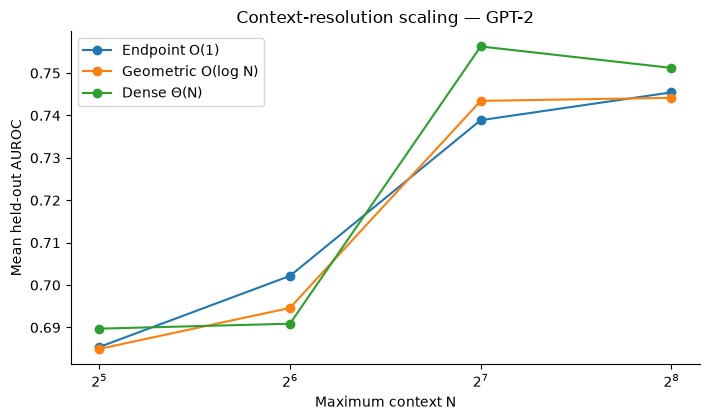

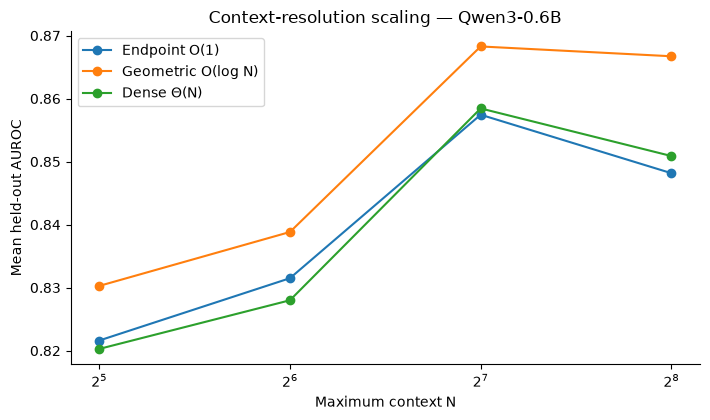

In [8]:
for scorer in summary["scorer"].unique():
    s = summary[summary["scorer"] == scorer].sort_values("N")

    fig, ax = plt.subplots(figsize=(7.2,4.3))

    ax.plot(s["N"], s["auc_endpoint"], marker="o", label="Endpoint O(1)")
    ax.plot(s["N"], s["auc_geometric"], marker="o", label="Geometric O(log N)")
    ax.plot(s["N"], s["auc_dense"], marker="o", label="Dense Θ(N)")

    ax.set_xscale("log", base=2)
    ax.set_xlabel("Maximum context N")
    ax.set_ylabel("Mean held-out AUROC")
    ax.set_title(f"Context-resolution scaling — {scorer}")
    ax.legend()
    ax.spines["top"].set_visible(False)
    ax.spines["right"].set_visible(False)

    fig.tight_layout()

    slug = scorer.lower().replace(".","").replace("-","_")
    fig.savefig(
        FIGURES / f"max_context_scaling_{slug}.pdf",
        bbox_inches="tight",
    )
    fig.savefig(
        FIGURES / f"max_context_scaling_{slug}.png",
        dpi=200,
        bbox_inches="tight",
    )

    plt.show()


# Figure 2 — Marginal gain decomposition

For each \(N\), compare:

- the gain from one endpoint to geometric probing;
- the additional gain from geometric probing to dense probing.

A strong saturation result has a large first gain and a very small second gain.


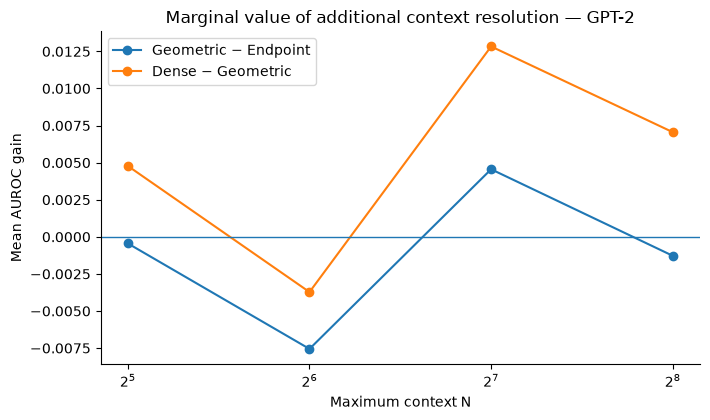

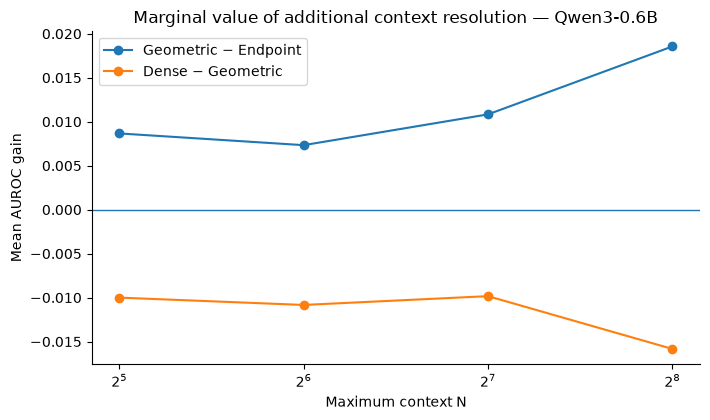

In [9]:
for scorer in summary["scorer"].unique():
    s = summary[summary["scorer"] == scorer].sort_values("N")

    fig, ax = plt.subplots(figsize=(7.2,4.3))

    ax.plot(
        s["N"],
        s["gain_endpoint_to_geometric"],
        marker="o",
        label="Geometric − Endpoint",
    )
    ax.plot(
        s["N"],
        s["gain_geometric_to_dense"],
        marker="o",
        label="Dense − Geometric",
    )

    ax.axhline(0, linewidth=1)
    ax.set_xscale("log", base=2)
    ax.set_xlabel("Maximum context N")
    ax.set_ylabel("Mean AUROC gain")
    ax.set_title(f"Marginal value of additional context resolution — {scorer}")
    ax.legend()
    ax.spines["top"].set_visible(False)
    ax.spines["right"].set_visible(False)

    fig.tight_layout()

    slug = scorer.lower().replace(".","").replace("-","_")
    fig.savefig(
        FIGURES / f"max_context_marginal_gain_{slug}.pdf",
        bbox_inches="tight",
    )
    fig.savefig(
        FIGURES / f"max_context_marginal_gain_{slug}.png",
        dpi=200,
        bbox_inches="tight",
    )

    plt.show()


# Figure 3 — Measurement count versus retained dense performance

This directly visualizes the scaling claim.

For each \(N\), the geometric representation uses

\[
m_G(N)=1+\log_2(N/8)
\]

measurements, whereas dense uses

\[
m_D(N)=N-7.
\]


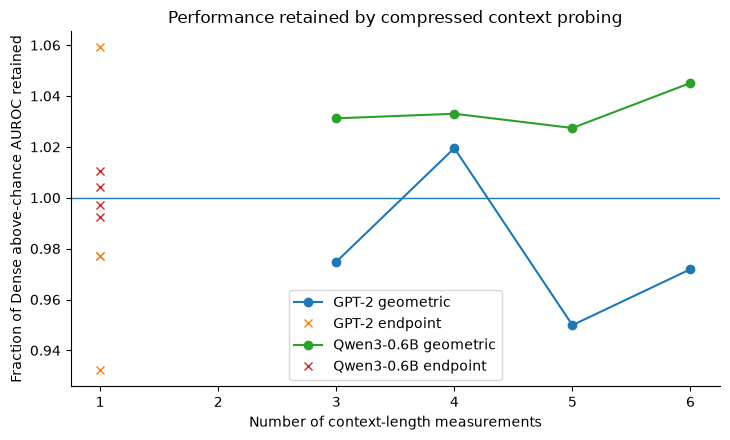

In [10]:
fig, ax = plt.subplots(figsize=(7.4,4.5))

for scorer in summary["scorer"].unique():
    s = summary[summary["scorer"] == scorer].sort_values("N")

    ax.plot(
        s["m_geometric"],
        s["geometric_retained_fraction"],
        marker="o",
        label=f"{scorer} geometric",
    )

    ax.plot(
        s["m_endpoint"],
        s["endpoint_retained_fraction"],
        marker="x",
        linestyle="none",
        label=f"{scorer} endpoint",
    )

ax.axhline(1.0, linewidth=1)
ax.set_xlabel("Number of context-length measurements")
ax.set_ylabel("Fraction of Dense above-chance AUROC retained")
ax.set_title("Performance retained by compressed context probing")
ax.legend()
ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)

fig.tight_layout()
fig.savefig(
    FIGURES / "max_context_scaling_retention.pdf",
    bbox_inches="tight",
)
fig.savefig(
    FIGURES / "max_context_scaling_retention.png",
    dpi=200,
    bbox_inches="tight",
)
plt.show()


# Interpretation checklist

The strongest result would be:

1. endpoint \(L_N\) already retains most dense attribution performance;
2. geometric probing adds a clear early gain;
3. dense probing beyond the geometric grid adds only a marginal and unstable gain;
4. the same qualitative pattern holds for both Qwen and GPT-2;
5. the geometric measurement count grows logarithmically with \(N\), while dense measurement count grows linearly.

If this pattern holds, a careful paper-level conclusion is:

> For source attribution, the effective context-length resolution is far lower than the dense resolution used for token-level CLP explanation. A constant-size endpoint measurement captures most discriminative value, while geometrically spaced \(O(\log N)\) probing recovers nearly all of the dense \(\Theta(N)\) response.

Do not claim \(O(\log\log N)\) unless a separate scaling experiment supports it.


In [11]:
print("=== MAX-CONTEXT SCALING SUMMARY ===")
display(summary)

print("\n=== SPLIT-LEVEL DELTAS ===")
display(deltas)

print("\n=== HELD-OUT DOMAIN ===")
display(
    transfer.pivot_table(
        index=["scorer","heldout_domain_label","N"],
        columns="method",
        values="auroc",
    )
)


=== MAX-CONTEXT SCALING SUMMARY ===


,scorer,N,m_endpoint,m_geometric,m_dense,auc_endpoint,auc_geometric,auc_dense,endpoint_retained_fraction,geometric_retained_fraction,gain_endpoint_to_geometric,gain_geometric_to_dense
0,GPT-2,32,1,3,25,0.685389,0.684944,0.689722,0.977160,0.974817,-0.000444,0.004778
1,GPT-2,64,1,4,57,0.702167,0.694611,0.690889,1.059080,1.019499,-0.007556,-0.003722
2,GPT-2,128,1,5,121,0.738889,0.743444,0.756278,0.932148,0.949924,0.004556,0.012833
3,GPT-2,256,1,6,249,0.745444,0.744167,0.751222,0.977001,0.971915,-0.001278,0.007056
4,Qwen3-0.6B,32,1,3,25,0.821611,0.830278,0.820278,1.004163,1.031223,0.008667,-0.010000
5,Qwen3-0.6B,64,1,4,57,0.831500,0.838833,0.828000,1.010671,1.033028,0.007333,-0.010833
6,Qwen3-0.6B,128,1,5,121,0.857444,0.868278,0.858444,0.997210,1.027433,0.010833,-0.009833
7,Qwen3-0.6B,256,1,6,249,0.848167,0.866722,0.850889,0.992242,1.045123,0.018556,-0.015833



=== SPLIT-LEVEL DELTAS ===


,scorer,N,comparison,mean_delta,median_delta,q25,q75,min,max,positive,n
0,GPT-2,32,Geometric vs Endpoint,-0.000444,1.666667e-03,-0.010556,0.016111,-0.078889,0.037778,11,20
1,GPT-2,32,Dense vs Geometric,0.004778,3.888889e-03,-0.000556,0.011389,-0.006667,0.018889,13,20
2,GPT-2,32,Dense vs Endpoint,0.004333,1.111111e-02,-0.006389,0.021667,-0.060000,0.050000,13,20
3,GPT-2,64,Geometric vs Endpoint,-0.007556,-1.111111e-03,-0.017778,0.005000,-0.080000,0.038889,9,20
4,GPT-2,64,Dense vs Geometric,-0.003722,-1.666667e-03,-0.012222,0.009167,-0.086667,0.041111,10,20
5,GPT-2,64,Dense vs Endpoint,-0.011278,-1.000000e-02,-0.031389,0.011944,-0.078889,0.044444,8,20
6,GPT-2,128,Geometric vs Endpoint,0.004556,1.166667e-02,-0.016944,0.019167,-0.053333,0.044444,13,20
7,GPT-2,128,Dense vs Geometric,0.012833,1.333333e-02,0.000556,0.024444,-0.012222,0.031111,15,20
8,GPT-2,128,Dense vs Endpoint,0.017389,1.666667e-02,0.004444,0.031389,-0.036667,0.066667,15,20
9,GPT-2,256,Geometric vs Endpoint,-0.001278,6.666667e-03,-0.015278,0.015000,-0.052222,0.033333,12,20



=== HELD-OUT DOMAIN ===


method                                  Dense  Endpoint  Geometric
scorer     heldout_domain_label N                                 
GPT-2      Essay                32   0.635633  0.638941   0.633743
                                64   0.647921  0.649338   0.640359
                                128  0.782136  0.735350   0.753308
                                256  0.788280  0.759452   0.756616
           Reuters              32   0.835485  0.842566   0.842566
                                64   0.839234  0.867972   0.868805
                                128  0.830071  0.885881   0.859642
                                256  0.842566  0.901291   0.872553
           Wikipedia            32   0.628220  0.619377   0.618608
                                64   0.638985  0.623606   0.624375
                                128  0.691657  0.657055   0.665513
                                256  0.677047  0.665513   0.673203
Qwen3-0.6B Essay                32   0.835539  0.835539   0.848299
                                64   0.836484  0.858223   0.834121
                                128  0.915879  0.899811   0.914934
                                256  0.883270  0.905009   0.915406
           Reuters              32   0.934611  0.927530   0.928363
                                64   0.895877  0.912953   0.907122
                                128  0.891712  0.921283   0.907539
                                256  0.889629  0.922949   0.904207
           Wikipedia            32   0.742791  0.787005   0.763168
                                64   0.771626  0.822376   0.786621
                                128  0.850058  0.875433   0.852749
                                256  0.877739  0.871972   0.857747